# DX799 Capstone — Week 8: K-Nearest Neighbors and Distance Metrics

This analysis compares KNN classification on the Statlog Heart Disease and Framingham datasets. The primary question is how scaling, distance metrics, and neighborhood size affect predictive performance, particularly for the minority CHD outcome in Framingham.

## 1. KNN and distance measures

KNN assigns a class using nearby observations. I examined Euclidean, Manhattan, Minkowski (p=3), and cosine distance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"AP": "average_precision", "AUC": "roc_auc", "F1": "f1"}


### Distance properties

Minkowski distance is equivalent to Manhattan distance when p=1 and Euclidean distance when p=2. As p increases, the largest feature difference increasingly dominates. Standardizing data changes its scale but does not remove outliers.

In [2]:
differences = np.array([3.0, 5.0])
print("Minkowski distance for differences [3, 5]:")
for p in [1, 2, 3, 10, 100, np.inf]:
    print(f"p={p}: {np.linalg.norm(differences, ord=p):.3f}")
example = np.r_[np.linspace(0, 1, 100), 100].reshape(-1, 1)
z = StandardScaler().fit_transform(example)
print(f"Outlier z-score after scaling: {z[-1, 0]:.2f} (still extreme)")

Minkowski distance for differences [3, 5]:
p=1: 8.000
p=2: 5.831
p=3: 5.337
p=10: 5.003
p=100: 5.000
p=inf: 5.000
Outlier z-score after scaling: 10.00 (still extreme)


## 2. Datasets

The same preprocessed Statlog Heart Disease and Framingham datasets from the earlier capstone analyses were used.

In [3]:
BASE = "https://raw.githubusercontent.com/piraterashik/DX799-Data-Science-Capstone/main/"
heart = pd.read_csv(BASE + "preprocessed_heart_disease.csv")
framingham = pd.read_csv(BASE + "preprocessed_framingham.csv")
print("Statlog:", heart.shape, "| Framingham:", framingham.shape)
display(heart.head(2), framingham.head(2))

Statlog: (270, 14) | Framingham: (4238, 16)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0


## 3. Exploratory data analysis

Statlog contains 270 observations, with 44.44% positive cases; Framingham contains 4,238 observations, with 15.20% positive cases. Framingham's class imbalance makes accuracy alone a poor measure of detection. I also examined numeric outliers to assess whether robust scaling could be useful.

,Dataset,Rows,Positive,Positive %,Missing cells
0,Statlog,270,120,44.44,0
1,Framingham,4238,644,15.20,0


,Dataset,Feature,IQR outliers,Outlier %
12,Framingham,glucose,262,6.18
1,Statlog,trestbps,9,3.33
8,Framingham,sysBP,126,2.97
10,Framingham,BMI,97,2.29
9,Framingham,diaBP,81,1.91
2,Statlog,chol,5,1.85
4,Statlog,oldpeak,4,1.48
3,Statlog,thalach,1,0.37


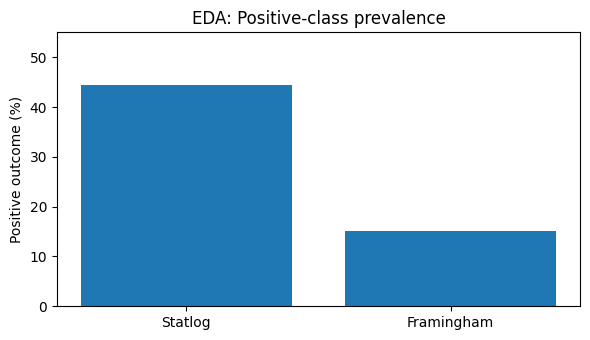

In [4]:
SPEC = {
    "Statlog": {"data": heart, "target": "target",
                "numeric": ["age", "trestbps", "chol", "thalach", "oldpeak"],
                "binary": ["sex", "fbs", "exang"],
                "categorical": ["cp", "restecg", "slope", "ca", "thal"]},
    "Framingham": {"data": framingham, "target": "TenYearCHD",
                   "numeric": ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"],
                   "binary": ["male", "currentSmoker", "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes"],
                   "categorical": ["education"]}
}
eda_rows, outlier_rows = [], []
for name, s in SPEC.items():
    df = s["data"]
    eda_rows.append({"Dataset": name, "Rows": len(df), "Positive": int(df[s["target"]].sum()),
                     "Positive %": round(100 * df[s["target"]].mean(), 2),
                     "Missing cells": int(df.isna().sum().sum())})
    for feature in s["numeric"]:
        x = df[feature].dropna()
        q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
        count = int(((x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)).sum()) if iqr else 0
        outlier_rows.append({"Dataset": name, "Feature": feature, "IQR outliers": count,
                             "Outlier %": round(100 * count / len(x), 2) if len(x) else np.nan})
eda = pd.DataFrame(eda_rows)
outliers = pd.DataFrame(outlier_rows)
display(eda)
display(outliers.sort_values("Outlier %", ascending=False).groupby("Dataset").head(4))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(eda["Dataset"], eda["Positive %"])
ax.set(ylabel="Positive outcome (%)", title="EDA: Positive-class prevalence", ylim=(0, 55))
plt.tight_layout(); plt.show()

## 4. Data splitting and preprocessing

Both datasets were divided into stratified 80/20 training and test sets (random state 42). Five-fold stratified cross-validation was used on the training data. Missing-value imputation, categorical encoding, and scaling were included in the modeling pipelines to prevent information leakage.

In [5]:
SPLITS = {}
for name, s in SPEC.items():
    features = s["numeric"] + s["binary"] + s["categorical"]
    X = s["data"][features].copy()
    y = s["data"][s["target"]].astype(int)
    SPLITS[name] = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
    Xtr, Xte, ytr, yte = SPLITS[name]
    print(f"{name}: train={len(Xtr)}, test={len(Xte)}, train positives={ytr.sum()}, test positives={yte.sum()}")

def make_knn(name, scale="standard", metric="euclidean", k=7, weights="uniform"):
    s = SPEC[name]
    scaler = {"none": "passthrough", "standard": StandardScaler(),
              "minmax": MinMaxScaler(), "robust": RobustScaler()}[scale]
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", scaler)])
    binary = Pipeline([("impute", SimpleImputer(strategy="most_frequent"))])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    prep = ColumnTransformer([("numeric", numeric, s["numeric"]),
                              ("binary", binary, s["binary"]),
                              ("category", categorical, s["categorical"])], sparse_threshold=0)
    return Pipeline([("prep", prep),
                     ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric,
                                                   p=3 if metric == "minkowski" else 2,
                                                   weights=weights, algorithm="brute"))])

def cv_row(name, model, label):
    Xtr, _, ytr, _ = SPLITS[name]
    scores = cross_validate(model, Xtr, ytr, cv=CV, scoring=SCORING, n_jobs=2)
    return {"Dataset": name, "Setting": label,
            **{f"CV {m}": round(scores[f"test_{m}"].mean(), 4) for m in SCORING}}

Statlog: train=216, test=54, train positives=96, test positives=24
Framingham: train=3390, test=848, train positives=515, test positives=129


## 5. Feature scaling

At k=7 with Euclidean distance, I compared unscaled features with standard, min–max, and robust scaling. Average precision (AP) is the principal measure of positive-class ranking performance.

In [6]:
scaling_results = pd.DataFrame([
    cv_row(name, make_knn(name, scale=scale), scale)
    for name in SPEC for scale in ["none", "standard", "minmax", "robust"]
])
display(scaling_results)
for name in SPEC:
    temp = scaling_results[scaling_results.Dataset == name]
    best = temp.loc[temp["CV AP"].idxmax()]
    print(f"{name}: highest scaling-study CV AP = {best['CV AP']:.3f} ({best['Setting']}).")

,Dataset,Setting,CV AP,CV AUC,CV F1
0,Statlog,none,0.5919,0.6514,0.5436
1,Statlog,standard,0.8643,0.8892,0.7992
2,Statlog,minmax,0.8792,0.8870,0.7861
3,Statlog,robust,0.8585,0.8861,0.7983
4,Framingham,none,0.2306,0.6363,0.1166
5,Framingham,standard,0.2358,0.6408,0.1206
6,Framingham,minmax,0.2242,0.6233,0.1235
7,Framingham,robust,0.2451,0.6386,0.1418


Statlog: highest scaling-study CV AP = 0.879 (minmax).
Framingham: highest scaling-study CV AP = 0.245 (robust).


## 6. Distance metrics

Euclidean, Manhattan, Minkowski (p=3), and cosine distance were evaluated with standardized features and k=7. The comparison held other settings constant to isolate the effect of the distance metric.

,Dataset,Setting,CV AP,CV AUC,CV F1
0,Statlog,euclidean,0.8643,0.8892,0.7992
1,Statlog,manhattan,0.8834,0.8968,0.7952
2,Statlog,minkowski,0.8482,0.8850,0.7763
3,Statlog,cosine,0.8532,0.8804,0.7984
4,Framingham,euclidean,0.2358,0.6408,0.1206
5,Framingham,manhattan,0.2375,0.6426,0.1135
6,Framingham,minkowski,0.2300,0.6295,0.1321
7,Framingham,cosine,0.2415,0.6525,0.1587


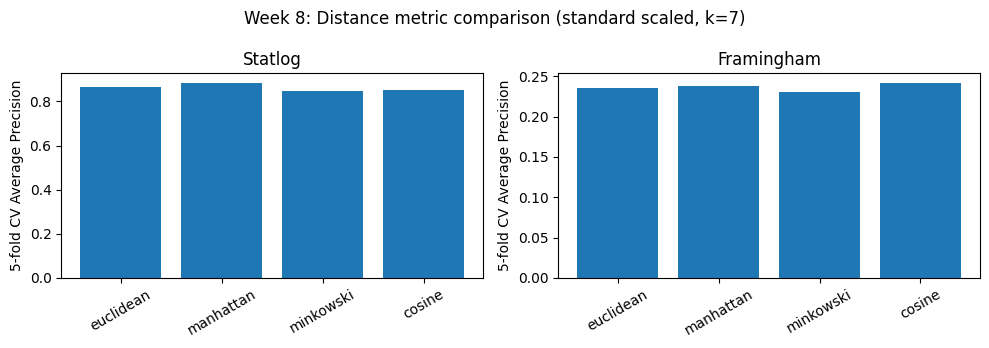

In [7]:
distance_results = pd.DataFrame([
    cv_row(name, make_knn(name, metric=metric), metric)
    for name in SPEC for metric in ["euclidean", "manhattan", "minkowski", "cosine"]
])
display(distance_results)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
for ax, name in zip(axes, SPEC):
    temp = distance_results[distance_results.Dataset == name]
    ax.bar(temp["Setting"], temp["CV AP"])
    ax.set(title=name, ylabel="5-fold CV Average Precision")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Week 8: Distance metric comparison (standard scaled, k=7)")
plt.tight_layout(); plt.show()

## 7. Neighborhood size and overfitting

Training and validation F1 scores were compared at k=1, 3, 7, 15, and 31. Very small neighborhoods can fit individual training cases closely, while larger neighborhoods produce smoother decisions.

,Dataset,k,Train F1,CV F1
0,Statlog,1,1.000,0.719
1,Statlog,3,0.878,0.778
2,Statlog,7,0.840,0.799
3,Statlog,15,0.786,0.763
4,Statlog,31,0.782,0.781
5,Framingham,1,1.000,0.226
6,Framingham,3,0.516,0.187
7,Framingham,7,0.235,0.121
8,Framingham,15,0.107,0.090
9,Framingham,31,0.036,0.027


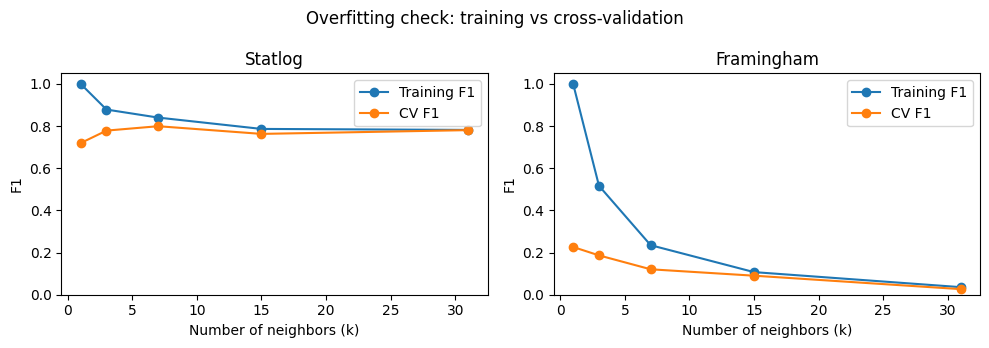

In [8]:
overfit_rows = []
for name in SPEC:
    Xtr, _, ytr, _ = SPLITS[name]
    for k in [1, 3, 7, 15, 31]:
        scores = cross_validate(make_knn(name, k=k), Xtr, ytr, cv=CV,
                                scoring="f1", return_train_score=True, n_jobs=2)
        overfit_rows.append({"Dataset": name, "k": k,
                             "Train F1": scores["train_score"].mean(),
                             "CV F1": scores["test_score"].mean()})
overfit_results = pd.DataFrame(overfit_rows)
display(overfit_results.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, name in zip(axes, SPEC):
    temp = overfit_results[overfit_results.Dataset == name]
    ax.plot(temp.k, temp["Train F1"], marker="o", label="Training F1")
    ax.plot(temp.k, temp["CV F1"], marker="o", label="CV F1")
    ax.set(title=name, xlabel="Number of neighbors (k)", ylabel="F1", ylim=(0, 1.05))
    ax.legend()
fig.suptitle("Overfitting check: training vs cross-validation")
plt.tight_layout(); plt.show()

## 8. Hyperparameter tuning

A five-fold grid search tested 3, 7, 15, and 31 neighbors; uniform and distance weighting; and four distance metrics. The configurations were ranked by cross-validation average precision. Here, k controls neighborhood size, weights determine the influence of nearby cases, and the distance metric defines which observations count as similar.

In [9]:
PARAM_GRID = [
    {"knn__metric": ["euclidean", "manhattan", "cosine"],
     "knn__n_neighbors": [3, 7, 15, 31], "knn__weights": ["uniform", "distance"]},
    {"knn__metric": ["minkowski"], "knn__p": [3],
     "knn__n_neighbors": [3, 7, 15, 31], "knn__weights": ["uniform", "distance"]}
]
SEARCHES = {}
for name in SPEC:
    Xtr, _, ytr, _ = SPLITS[name]
    search = GridSearchCV(make_knn(name), param_grid=PARAM_GRID,
                          scoring="average_precision", cv=CV, n_jobs=2,
                          return_train_score=True, refit=True)
    search.fit(Xtr, ytr)
    SEARCHES[name] = search
    print(f"{name}: best CV AP={search.best_score_:.4f}, parameters={search.best_params_}")
    top = (pd.DataFrame(search.cv_results_)
           .sort_values("rank_test_score")
           [["params", "mean_train_score", "mean_test_score", "std_test_score"]].head(5))
    display(top)

Statlog: best CV AP=0.9137, parameters={'knn__metric': 'manhattan', 'knn__n_neighbors': 31, 'knn__weights': 'distance'}


,params,mean_train_score,mean_test_score,std_test_score
15,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.00000,0.913707,0.033789
7,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",1.00000,0.903330,0.041300
14,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.91236,0.902588,0.036317
13,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.00000,0.901792,0.040358
23,"{'knn__metric': 'cosine', 'knn__n_neighbors': ...",1.00000,0.899834,0.047389


Framingham: best CV AP=0.3209, parameters={'knn__metric': 'euclidean', 'knn__n_neighbors': 31, 'knn__weights': 'distance'}


,params,mean_train_score,mean_test_score,std_test_score
7,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",1.000000,0.320889,0.028797
31,"{'knn__metric': 'minkowski', 'knn__n_neighbors...",1.000000,0.316507,0.028007
15,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.000000,0.312119,0.017534
23,"{'knn__metric': 'cosine', 'knn__n_neighbors': ...",1.000000,0.307121,0.018471
6,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.372618,0.303058,0.028947


## 9. Classification thresholds

An F1-maximizing threshold was selected from out-of-fold training predictions, then compared with the default 0.50 threshold on the held-out test set. The threshold experiment examines the balance between case detection and false positives.

In [10]:
THRESHOLDS = {}
for name, search in SEARCHES.items():
    Xtr, _, ytr, _ = SPLITS[name]
    probs_oof = cross_val_predict(search.best_estimator_, Xtr, ytr,
                                 cv=CV, method="predict_proba", n_jobs=2)[:, 1]
    candidates = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = [f1_score(ytr, probs_oof >= t, zero_division=0) for t in candidates]
    best_index = int(np.argmax(f1s))
    THRESHOLDS[name] = float(candidates[best_index])
    print(f"{name}: training-OOF F1-optimal threshold={THRESHOLDS[name]:.2f} "
          f"(OOF F1={f1s[best_index]:.3f})")

Statlog: training-OOF F1-optimal threshold=0.42 (OOF F1=0.809)
Framingham: training-OOF F1-optimal threshold=0.16 (OOF F1=0.359)


## 10. Held-out evaluation

The tuned models were evaluated using precision, recall, F1, ROC AUC, AP, and confusion matrices. The test comparison reports how many positive cases were found and how many negative cases were incorrectly flagged.

,Dataset,Strategy,Threshold,Accuracy,Precision,Recall,F1,AUC,AP,TP,FP,TN,FN,Flagged
0,Statlog,KNN: 0.50,0.50,0.852,0.833,0.833,0.833,0.924,0.894,20,4,26,4,24
1,Statlog,KNN: CV threshold,0.42,0.833,0.800,0.833,0.816,0.924,0.894,20,5,25,4,25
2,Framingham,KNN: 0.50,0.50,0.848,0.500,0.016,0.030,0.661,0.248,2,2,717,127,4
3,Framingham,KNN: CV threshold,0.16,0.677,0.236,0.504,0.322,0.661,0.248,65,210,509,64,275


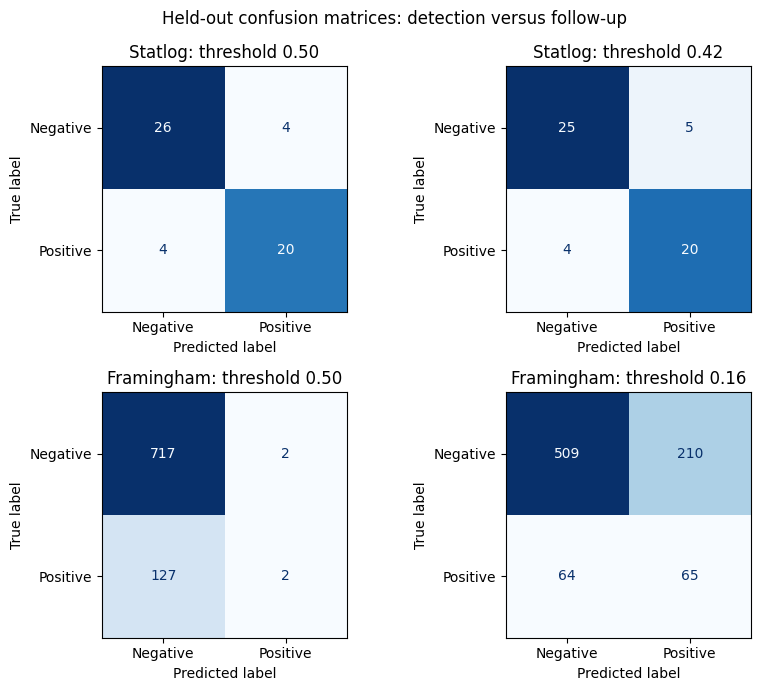

In [11]:
def heldout_metrics(name, model, threshold, label):
    _, Xte, _, yte = SPLITS[name]
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    return {"Dataset": name, "Strategy": label, "Threshold": threshold,
            "Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred, zero_division=0),
            "F1": f1_score(yte, pred, zero_division=0),
            "AUC": roc_auc_score(yte, proba),
            "AP": average_precision_score(yte, proba),
            "TP": tp, "FP": fp, "TN": tn, "FN": fn, "Flagged": int(pred.sum())}

final_rows = []
for name, search in SEARCHES.items():
    final_rows.append(heldout_metrics(name, search.best_estimator_, 0.50, "KNN: 0.50"))
    final_rows.append(heldout_metrics(name, search.best_estimator_, THRESHOLDS[name],
                                      "KNN: CV threshold"))
final_results = pd.DataFrame(final_rows)
display(final_results.round(3))

fig, axes = plt.subplots(2, 2, figsize=(8.5, 7))
for row, name in enumerate(SPEC):
    _, Xte, _, yte = SPLITS[name]
    proba = SEARCHES[name].best_estimator_.predict_proba(Xte)[:, 1]
    for col, threshold in enumerate([0.5, THRESHOLDS[name]]):
        pred = proba >= threshold
        cm = confusion_matrix(yte, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(
            ax=axes[row, col], cmap="Blues", colorbar=False)
        axes[row, col].set_title(f"{name}: threshold {threshold:.2f}")
fig.suptitle("Held-out confusion matrices: detection versus follow-up")
plt.tight_layout(); plt.show()

## 11. Discussion and conclusion

Scaling had a large effect on Statlog KNN performance. At k=7 with Euclidean distance, standard scaling increased cross-validation AP from 0.592 to 0.864, and min–max scaling reached 0.879. The effect was much smaller in Framingham: standard scaling improved AP from 0.231 to 0.236, while robust scaling yielded 0.245. This difference was notable given the numeric outliers found during EDA.

After tuning, both models selected k=31 with distance weighting. Manhattan distance achieved the highest cross-validation AP for Statlog (0.914), while Euclidean distance was selected for Framingham (0.321). The separate fixed-k metric comparison is not identical to this tuned-model comparison. Neighborhood size also affected generalization: on Framingham, k=1 produced a training F1 of 1.000 but a validation F1 of 0.226, indicating overfitting.

For the Framingham held-out sample, changing the classification threshold from 0.50 to 0.16 increased recall from 0.016 to 0.504 and identified 65 rather than 2 positive cases. False positives increased from 2 to 210, however. The tuned KNN model's held-out AUC was 0.661, so the threshold change improved detection at a substantial follow-up cost without changing ranking performance. These findings support further investigation of the sensitivity–false-positive tradeoff, but the models are not externally or clinically validated. Statlog and Framingham results should not be interpreted as directly interchangeable because their prediction targets and populations differ.

In [12]:
for name in SPEC:
    s = scaling_results[scaling_results.Dataset == name]
    d = distance_results[distance_results.Dataset == name]
    f = final_results[final_results.Dataset == name].set_index("Strategy")
    std = s.loc[s.Setting == "standard", "CV AP"].iloc[0]
    raw = s.loc[s.Setting == "none", "CV AP"].iloc[0]
    best_metric = d.loc[d["CV AP"].idxmax()]
    ordinary, adjusted = f.loc["KNN: 0.50"], f.loc["KNN: CV threshold"]
    print(f"\n{name}: Standard vs unscaled CV AP: {std:.3f} vs {raw:.3f} (delta {std-raw:+.3f}).")
    print(f"  Best fixed-k metric: {best_metric['Setting']} (CV AP {best_metric['CV AP']:.3f}).")
    print(f"  Test recall: {ordinary['Recall']:.3f} -> {adjusted['Recall']:.3f}; "
          f"false positives: {int(ordinary['FP'])} -> {int(adjusted['FP'])}.")



Statlog: Standard vs unscaled CV AP: 0.864 vs 0.592 (delta +0.272).
  Best fixed-k metric: manhattan (CV AP 0.883).
  Test recall: 0.833 -> 0.833; false positives: 4 -> 5.

Framingham: Standard vs unscaled CV AP: 0.236 vs 0.231 (delta +0.005).
  Best fixed-k metric: cosine (CV AP 0.241).
  Test recall: 0.016 -> 0.504; false positives: 2 -> 210.


## 12. Results and references

Six result tables are exported for use in the Milestone Two analysis.

**Datasets:** Statlog Heart Disease (UCI Machine Learning Repository) and Framingham Heart Study dataset, accessed from the capstone repository.

**Methods:** [Scikit-learn — Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html).

In [13]:
for name, table in {"week8_eda.csv": eda,
                    "week8_outliers.csv": outliers,
                    "week8_scaling_cv.csv": scaling_results,
                    "week8_distances_cv.csv": distance_results,
                    "week8_overfitting_cv.csv": overfit_results,
                    "week8_test_metrics.csv": final_results}.items():
    table.to_csv(name, index=False)
